# Part 2: Deep Learning Baselines

This notebook creates separate deep learning baselines for the existing rolling-window pipeline without modifying the LightGBM notebook.

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from IPython.display import display
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
START_DATE = "2010-01-01"
END_DATE = "2022-12-31"
TARGET_COL = "target_5d_cs"
REALIZED_RETURN_COL = "target_5d_raw"
REBALANCE_EVERY_N_DAYS = 5
LONG_SHORT_FRACTION = 0.20
TRANSACTION_COST = 0.0005
MIN_NAMES = 10

SEQUENCE_LENGTH = 20
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.1
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 5
TRANSFORMER_NHEAD = 4
TRANSFORMER_FF_DIM = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(RANDOM_STATE)
universe = [
        "NVDA", "AMD", "INTC", "QCOM", "AVGO", "TXN", "MU", "ADI",
        "MRVL", "MCHP", "MPWR", "ON", "NXPI", "SWKS", "QRVO",
        "LSCC", "CRUS", "DIOD", "POWI", "ALGM",
        "AMAT", "LRCX", "KLAC", "TER", "ENTG", "ACLS", "AEHR",
        "ASML", "ASX", "UCTT", "FORM", "COHR",
        "TSM", "UMC", "STM", "GFS",
        "SNPS", "CDNS", "ANSS",
        "AAPL", "MSFT", "GOOGL", "META", "AMZN",
        "DELL", "HPQ", "SMCI", "HPE", "ARW", "AVT",
    ]


Using device: cuda


## Data Download

In [2]:
raw_data = yf.download(
    universe,
    start="2010-01-01",
    end="2022-12-31",
    auto_adjust=True,
    progress=True,
    group_by="ticker",
    threads=True,
)

print(f"Downloaded data for {len(universe)} requested tickers.")


[**********************96%*********************  ]  48 of 50 completedERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ANSS"}}}
[*********************100%***********************]  50 of 50 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['ANSS']: YFTzMissingError('possibly delisted; no timezone found')


Downloaded data for 50 requested tickers.


## Feature Engineering

In [3]:
def make_price_panel(raw_data, requested_universe):
    frames = []
    valid_tickers = []

    for ticker in requested_universe:
        try:
            px = raw_data[ticker].copy()
        except Exception:
            continue

        if px.empty or "Close" not in px.columns or px["Close"].dropna().empty:
            continue

        keep_cols = [c for c in ["Open", "High", "Low", "Close", "Volume"] if c in px.columns]
        px = px[keep_cols].copy()
        px["code"] = ticker
        frames.append(px.reset_index().rename(columns={"Date": "date"}))
        valid_tickers.append(ticker)

    if not frames:
        raise ValueError("No valid tickers were downloaded.")

    df = pd.concat(frames, ignore_index=True)
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values(["code", "date"]).reset_index(drop=True)

    price_cols = ["Open", "High", "Low", "Close"]
    df[price_cols] = df.groupby("code")[price_cols].ffill()
    df["Volume"] = df.groupby("code")["Volume"].transform(lambda x: x.fillna(0))
    df["Return"] = df.groupby("code")["Close"].pct_change()
    df = df.dropna(subset=price_cols + ["Return"]).reset_index(drop=True)
    return df, valid_tickers


def add_technical_features(df):
    df = df.sort_values(["code", "date"]).reset_index(drop=True).copy()
    g = df.groupby("code", group_keys=False)
    f = pd.DataFrame(index=df.index)

    f["open_1"] = g["Open"].shift(1)
    f["high_1"] = g["High"].shift(1)
    f["low_1"] = g["Low"].shift(1)
    f["close_1"] = g["Close"].shift(1)
    f["close_2"] = g["Close"].shift(2)
    f["volume_1"] = g["Volume"].shift(1)
    f["log_volume_1"] = np.log1p(f["volume_1"])

    f["overnight_gap_1"] = f["open_1"] / f["close_2"] - 1
    f["intraday_return_1"] = f["close_1"] / f["open_1"] - 1
    f["high_low_range_1"] = f["high_1"] / f["low_1"] - 1
    f["high_close_range_1"] = f["high_1"] / f["close_1"] - 1
    f["low_close_range_1"] = f["low_1"] / f["close_1"] - 1
    f["close_position_1"] = (f["close_1"] - f["low_1"]) / (f["high_1"] - f["low_1"]).replace(0, np.nan)
    f["candle_body_1"] = (f["close_1"] - f["open_1"]) / f["open_1"]
    f["candle_body_abs_1"] = f["candle_body_1"].abs()
    f["upper_shadow_1"] = (f["high_1"] - np.maximum(f["open_1"], f["close_1"])) / f["close_1"]
    f["lower_shadow_1"] = (np.minimum(f["open_1"], f["close_1"]) - f["low_1"]) / f["close_1"]

    for window in [1, 2, 5, 10, 20, 60, 120, 250]:
        f[f"return_{window}"] = g["Close"].transform(lambda x, w=window: (x / x.shift(w) - 1).shift(1))
    for window in [1, 5, 20, 60, 250]:
        f[f"log_return_{window}"] = g["Close"].transform(lambda x, w=window: np.log(x).diff(w).shift(1))

    f["momentum_20_minus_5"] = f["return_20"] - f["return_5"]
    f["momentum_60_minus_20"] = f["return_60"] - f["return_20"]
    f["momentum_250_minus_60"] = f["return_250"] - f["return_60"]

    for window in [5, 20, 60, 250]:
        f[f"ret_mean_{window}"] = g["Close"].transform(lambda x, w=window: x.pct_change().rolling(w).mean().shift(1))
        f[f"ret_std_{window}"] = g["Close"].transform(lambda x, w=window: x.pct_change().rolling(w).std().shift(1))
        f[f"sharpe_{window}"] = f[f"ret_mean_{window}"] / f[f"ret_std_{window}"]

    for window in [20, 60]:
        f[f"ret_skew_{window}"] = g["Close"].transform(lambda x, w=window: x.pct_change().rolling(w).skew().shift(1))
        f[f"ret_kurt_{window}"] = g["Close"].transform(lambda x, w=window: x.pct_change().rolling(w).kurt().shift(1))

    f["return_5_to_vol_20"] = f["return_5"] / f["ret_std_20"]
    f["return_20_to_vol_60"] = f["return_20"] / f["ret_std_60"]

    ma = {}
    for window in [5, 10, 20, 60, 120, 250]:
        ma[window] = g["Close"].transform(lambda x, w=window: x.rolling(w).mean().shift(1))
        f[f"close_to_ma_{window}"] = f["close_1"] / ma[window] - 1

    f["ma_5_to_20"] = ma[5] / ma[20] - 1
    f["ma_10_to_20"] = ma[10] / ma[20] - 1
    f["ma_20_to_60"] = ma[20] / ma[60] - 1
    f["ma_60_to_120"] = ma[60] / ma[120] - 1
    f["ma_60_to_250"] = ma[60] / ma[250] - 1
    f["ma_120_to_250"] = ma[120] / ma[250] - 1

    for window in [20, 60]:
        price_std = g["Close"].transform(lambda x, w=window: x.rolling(w).std().shift(1))
        f[f"bollinger_z_{window}"] = (f["close_1"] - ma[window]) / price_std
        f[f"bollinger_width_{window}"] = 4 * price_std / ma[window]

    for window in [20, 60, 250]:
        rolling_high = g["High"].transform(lambda x, w=window: x.rolling(w).max().shift(1))
        rolling_low = g["Low"].transform(lambda x, w=window: x.rolling(w).min().shift(1))
        f[f"dist_to_high_{window}"] = f["close_1"] / rolling_high - 1
        f[f"dist_to_low_{window}"] = f["close_1"] / rolling_low - 1
        f[f"range_position_{window}"] = (f["close_1"] - rolling_low) / (rolling_high - rolling_low).replace(0, np.nan)
        f[f"drawdown_{window}"] = f["close_1"] / rolling_high - 1

    prev_close = g["Close"].shift(1)
    true_range = pd.concat([
        df["High"] - df["Low"],
        (df["High"] - prev_close).abs(),
        (df["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    tr_df = pd.DataFrame({"code": df["code"], "true_range": true_range})
    tr_g = tr_df.groupby("code", group_keys=False)
    for window in [14, 20, 60]:
        f[f"natr_{window}"] = tr_g["true_range"].transform(lambda x, w=window: x.rolling(w).mean().shift(1)) / f["close_1"]

    def rsi(x, window):
        diff = x.diff()
        gain = diff.clip(lower=0).rolling(window).mean()
        loss = (-diff.clip(upper=0)).rolling(window).mean()
        return (100 - 100 / (1 + gain / loss)).shift(1)

    f["rsi_14"] = g["Close"].transform(lambda x: rsi(x, 14))
    f["rsi_28"] = g["Close"].transform(lambda x: rsi(x, 28))
    f["ema_12_to_26"] = g["Close"].transform(lambda x: (x.ewm(span=12, adjust=False).mean() / x.ewm(span=26, adjust=False).mean() - 1).shift(1))
    f["ema_20_to_60"] = g["Close"].transform(lambda x: (x.ewm(span=20, adjust=False).mean() / x.ewm(span=60, adjust=False).mean() - 1).shift(1))
    macd_signal = g["Close"].transform(
        lambda x: ((x.ewm(span=12, adjust=False).mean() - x.ewm(span=26, adjust=False).mean()) / x.ewm(span=26, adjust=False).mean()).ewm(span=9, adjust=False).mean().shift(1)
    )
    f["macd_signal_9"] = macd_signal
    f["macd_hist"] = f["ema_12_to_26"] - f["macd_signal_9"]

    for window in [1, 5, 20]:
        f[f"volume_log_change_{window}"] = g["Volume"].transform(lambda x, w=window: np.log1p(x).diff(w).shift(1))

    log_volume = np.log1p(df["Volume"])
    lv_df = pd.DataFrame({"code": df["code"], "log_volume": log_volume})
    lv_g = lv_df.groupby("code", group_keys=False)
    for window in [20, 60]:
        lv_mean = lv_g["log_volume"].transform(lambda x, w=window: x.rolling(w).mean().shift(1))
        lv_std = lv_g["log_volume"].transform(lambda x, w=window: x.rolling(w).std().shift(1))
        f[f"relative_log_volume_{window}"] = f["log_volume_1"] - lv_mean
        f[f"volume_zscore_{window}"] = (f["log_volume_1"] - lv_mean) / lv_std
        f[f"volume_rank_{window}"] = lv_g["log_volume"].transform(lambda x, w=window: x.rolling(w).rank(pct=True).shift(1))

    dollar_volume = df["Close"] * df["Volume"]
    dv_df = pd.DataFrame({"code": df["code"], "dollar_volume": dollar_volume})
    dv_g = dv_df.groupby("code", group_keys=False)
    for window in [1, 5, 20]:
        f[f"dollar_volume_log_change_{window}"] = dv_g["dollar_volume"].transform(lambda x, w=window: np.log1p(x).diff(w).shift(1))

    cs_base = pd.concat([df[["date"]], f], axis=1)
    for col in ["return_1", "return_5", "return_20", "return_60", "ret_std_20", "ret_std_60", "volume_zscore_20", "close_to_ma_20", "range_position_60"]:
        f[f"{col}_cs_rank"] = cs_base.groupby("date")[col].rank(pct=True)

    f["day_of_week"] = df["date"].dt.dayofweek
    f["month"] = df["date"].dt.month
    f["quarter"] = df["date"].dt.quarter
    f["is_month_start"] = df["date"].dt.is_month_start.astype(int)
    f["is_month_end"] = df["date"].dt.is_month_end.astype(int)
    f["is_quarter_start"] = df["date"].dt.is_quarter_start.astype(int)
    f["is_quarter_end"] = df["date"].dt.is_quarter_end.astype(int)

    out = pd.concat([df, f], axis=1)
    out = out.replace([np.inf, -np.inf], np.nan)
    return out


def prepare_model_data(df):
    work = df.copy()
    work = work[(work["date"] >= START_DATE) & (work["date"] <= END_DATE)].copy()
    work["target_5d_raw"] = work.groupby("code")["Close"].shift(-5) / work["Close"] - 1
    work["target_5d_cs"] = work["target_5d_raw"] - work.groupby("date")["target_5d_raw"].transform("mean")

    base_cols = [
        "date", "code", "Open", "High", "Low", "Close", "Volume", "Return",
        "target_5d_raw", "target_5d_cs",
    ]
    feature_cols = [c for c in work.columns if c not in base_cols]
    work = work.dropna(subset=feature_cols + ["target_5d_raw", "target_5d_cs"]).copy()
    work = work.sort_values(["date", "code"]).reset_index(drop=True)
    return work, feature_cols


price_df, valid_tickers = make_price_panel(raw_data, universe)
feature_df = add_technical_features(price_df)
model_df, feature_cols = prepare_model_data(feature_df)

print(f"Valid tickers: {len(valid_tickers)} / {len(universe)}")
print(f"Model rows: {len(model_df):,}")
print(f"Feature count: {len(feature_cols)}")
display(model_df[["date", "code", "target_5d_raw", "target_5d_cs"]].head())


/tmp/ipykernel_854/1205348389.py:153: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  f[f"{col}_cs_rank"] = cs_base.groupby("date")[col].rank(pct=True)
/tmp/ipykernel_854/1205348389.py:153: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  f[f"{col}_cs_rank"] = cs_base.groupby("date")[col].rank(pct=True)
/tmp/ipykernel_854/1205348389.py:153: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.con

Valid tickers: 49 / 50
Model rows: 136,773
Feature count: 116


,date,code,target_5d_raw,target_5d_cs
0,2011-01-03,AAPL,0.039081,0.018223
1,2011-01-03,ACLS,-0.116022,-0.136880
2,2011-01-03,ADI,-0.006587,-0.027445
3,2011-01-03,AEHR,0.118644,0.097786
4,2011-01-03,AMAT,-0.020626,-0.041484


## Rolling Fold Definition

In [4]:
def create_time_split(df_model, spec, date_col="date"):
    df_sorted = df_model.sort_values([date_col, "code"]).copy()
    return {
        "train": df_sorted[df_sorted[date_col].between(spec["train_start"], spec["train_end"])].copy(),
        "validation": df_sorted[df_sorted[date_col].between(spec["val_start"], spec["val_end"])].copy(),
        "test": df_sorted[df_sorted[date_col].between(spec["test_start"], spec["test_end"])].copy(),
    }


FOLD_SPECS = [
    {
        "fold_name": "Fold 1",
        "train_start": "2011-01-01",
        "train_end": "2015-12-31",
        "val_start": "2016-01-01",
        "val_end": "2016-12-31",
        "test_start": "2017-01-01",
        "test_end": "2017-12-31",
    },
    {
        "fold_name": "Fold 2",
        "train_start": "2012-01-01",
        "train_end": "2016-12-31",
        "val_start": "2017-01-01",
        "val_end": "2017-12-31",
        "test_start": "2018-01-01",
        "test_end": "2018-12-31",
    },
    {
        "fold_name": "Fold 3",
        "train_start": "2013-01-01",
        "train_end": "2017-12-31",
        "val_start": "2018-01-01",
        "val_end": "2018-12-31",
        "test_start": "2019-01-01",
        "test_end": "2019-12-31",
    },
    {
        "fold_name": "Fold 4",
        "train_start": "2014-01-01",
        "train_end": "2018-12-31",
        "val_start": "2019-01-01",
        "val_end": "2019-12-31",
        "test_start": "2020-01-01",
        "test_end": "2020-12-31",
    },
    {
        "fold_name": "Fold 5",
        "train_start": "2015-01-01",
        "train_end": "2019-12-31",
        "val_start": "2020-01-01",
        "val_end": "2020-12-31",
        "test_start": "2021-01-01",
        "test_end": "2021-12-31",
    },
    {
        "fold_name": "Fold 6",
        "train_start": "2016-01-01",
        "train_end": "2020-12-31",
        "val_start": "2021-01-01",
        "val_end": "2021-12-31",
        "test_start": "2022-01-01",
        "test_end": "2022-12-31",
    },
]

display(pd.DataFrame(FOLD_SPECS))


,fold_name,train_start,train_end,val_start,val_end,test_start,test_end
0,Fold 1,2011-01-01,2015-12-31,2016-01-01,2016-12-31,2017-01-01,2017-12-31
1,Fold 2,2012-01-01,2016-12-31,2017-01-01,2017-12-31,2018-01-01,2018-12-31
2,Fold 3,2013-01-01,2017-12-31,2018-01-01,2018-12-31,2019-01-01,2019-12-31
3,Fold 4,2014-01-01,2018-12-31,2019-01-01,2019-12-31,2020-01-01,2020-12-31
4,Fold 5,2015-01-01,2019-12-31,2020-01-01,2020-12-31,2021-01-01,2021-12-31
5,Fold 6,2016-01-01,2020-12-31,2021-01-01,2021-12-31,2022-01-01,2022-12-31


## Sequence Dataset Construction

In [5]:
class SequenceDataset(Dataset):
    def __init__(self, sequences, targets):
        self.sequences = torch.tensor(sequences, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.sequences[idx], self.targets[idx]


def build_sequences_for_split(df_split, feature_cols, scaler, sequence_length=SEQUENCE_LENGTH):
    rows = []

    for ticker, part in df_split.groupby("code", sort=True):
        part = part.sort_values("date").reset_index(drop=True).copy()
        scaled_features = scaler.transform(part[feature_cols])
        targets = part[TARGET_COL].to_numpy(dtype=np.float32)
        realized = part[REALIZED_RETURN_COL].to_numpy(dtype=np.float32)
        dates = part["date"].to_numpy()

        for end_idx in range(sequence_length - 1, len(part)):
            start_idx = end_idx - sequence_length + 1
            rows.append({
                "sequence": scaled_features[start_idx:end_idx + 1].astype(np.float32),
                "target": targets[end_idx],
                "actual_forward_return": realized[end_idx],
                "date": pd.Timestamp(dates[end_idx]),
                "ticker": ticker,
            })

    if not rows:
        raise ValueError("No valid sequences were created. Check split sizes and sequence length.")

    seq_df = pd.DataFrame(rows)
    return seq_df


def build_fold_sequence_data(train_df, val_df, test_df, feature_cols, sequence_length=SEQUENCE_LENGTH):
    scaler = StandardScaler()
    scaler.fit(train_df[feature_cols])

    train_seq_df = build_sequences_for_split(train_df, feature_cols, scaler, sequence_length=sequence_length)
    val_seq_df = build_sequences_for_split(val_df, feature_cols, scaler, sequence_length=sequence_length)
    test_seq_df = build_sequences_for_split(test_df, feature_cols, scaler, sequence_length=sequence_length)

    return {
        "scaler": scaler,
        "train_seq_df": train_seq_df,
        "val_seq_df": val_seq_df,
        "test_seq_df": test_seq_df,
    }


sample_split = create_time_split(model_df, FOLD_SPECS[0])
sample_sequence_data = build_fold_sequence_data(
    sample_split["train"],
    sample_split["validation"],
    sample_split["test"],
    feature_cols,
    sequence_length=SEQUENCE_LENGTH,
)

print("Sample fold sequence counts:")
print(f"Train sequences: {len(sample_sequence_data['train_seq_df']):,}")
print(f"Validation sequences: {len(sample_sequence_data['val_seq_df']):,}")
print(f"Test sequences: {len(sample_sequence_data['test_seq_df']):,}")
display(sample_sequence_data["train_seq_df"][["date", "ticker", "target", "actual_forward_return"]].head())


Sample fold sequence counts:
Train sequences: 53,650
Validation sequences: 10,509
Test sequences: 10,747


,date,ticker,target,actual_forward_return
0,2011-01-31,AAPL,-0.019606,0.037015
1,2011-02-01,AAPL,-0.001566,0.029476
2,2011-02-02,AAPL,0.016609,0.040196
3,2011-02-03,AAPL,0.007742,0.032320
4,2011-02-04,AAPL,0.021497,0.029870


## PyTorch Model Definitions

In [6]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.rnn = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        last_hidden = self.dropout(output[:, -1, :])
        return self.head(last_hidden).squeeze(-1)


class GRURegressor(nn.Module):
    def __init__(self, input_size, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.rnn = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        last_hidden = self.dropout(output[:, -1, :])
        return self.head(last_hidden).squeeze(-1)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class TransformerEncoderRegressor(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size=HIDDEN_SIZE,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        nhead=TRANSFORMER_NHEAD,
        dim_feedforward=TRANSFORMER_FF_DIM,
    ):
        super().__init__()
        self.input_projection = nn.Linear(input_size, hidden_size)
        self.position_encoding = PositionalEncoding(hidden_size, max_len=SEQUENCE_LENGTH + 32)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_size,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = self.input_projection(x)
        x = self.position_encoding(x)
        x = self.encoder(x)
        last_hidden = self.dropout(x[:, -1, :])
        return self.head(last_hidden).squeeze(-1)


MODEL_BUILDERS = {
    "LSTM": lambda input_size: LSTMRegressor(input_size=input_size),
    "GRU": lambda input_size: GRURegressor(input_size=input_size),
    "Transformer": lambda input_size: TransformerEncoderRegressor(input_size=input_size),
}


## Training and Prediction Utilities

In [7]:
def get_rebalance_dates(df_eval, every_n_days=REBALANCE_EVERY_N_DAYS):
    dates = np.array(sorted(pd.to_datetime(df_eval["date"].unique())))
    return dates[::every_n_days]


def build_long_short_weights(
    df_eval,
    signal_col,
    top_frac=LONG_SHORT_FRACTION,
    rebalance_dates=None,
    min_names=MIN_NAMES,
    date_col="date",
    code_col="code",
):
    if rebalance_dates is None:
        rebalance_dates = get_rebalance_dates(df_eval)

    weight_frames = []
    for date in rebalance_dates:
        cross_section = df_eval.loc[df_eval[date_col] == date, [date_col, code_col, signal_col]].dropna().copy()
        n = len(cross_section)
        if n < min_names:
            continue

        n_bucket = max(1, int(np.floor(n * top_frac)))
        cross_section = cross_section.sort_values(signal_col, ascending=False)
        longs = cross_section.head(n_bucket).copy()
        shorts = cross_section.tail(n_bucket).copy()

        longs["weight"] = 0.5 / len(longs)
        shorts["weight"] = -0.5 / len(shorts)
        weight_frames.append(pd.concat([longs, shorts], ignore_index=True)[[date_col, code_col, "weight"]])

    if not weight_frames:
        return pd.DataFrame(columns=[date_col, code_col, "weight"])
    return pd.concat(weight_frames, ignore_index=True)


def long_short_backtest(df_eval, weights, target_col=REALIZED_RETURN_COL, transaction_cost=TRANSACTION_COST, date_col="date", code_col="code"):
    df_bt = weights.merge(df_eval[[date_col, code_col, target_col]], on=[date_col, code_col], how="left")
    df_bt = df_bt.dropna(subset=[target_col, "weight"]).copy()

    rows = []
    prev_weights = pd.Series(dtype=float)
    for date, part in df_bt.groupby(date_col, sort=True):
        current_weights = part.set_index(code_col)["weight"].astype(float)
        all_names = current_weights.index.union(prev_weights.index)
        turnover = (current_weights.reindex(all_names, fill_value=0.0) - prev_weights.reindex(all_names, fill_value=0.0)).abs().sum()
        gross_return = (part["weight"] * part[target_col]).sum()
        cost = transaction_cost * turnover
        net_return = gross_return - cost

        rows.append({
            "date": pd.Timestamp(date),
            "gross_return": gross_return,
            "net_return": net_return,
            "turnover": turnover,
            "cost": cost,
            "n_positions": len(current_weights),
        })
        prev_weights = current_weights

    result = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    if result.empty:
        return result

    result["gross_equity"] = (1 + result["gross_return"]).cumprod()
    result["net_equity"] = (1 + result["net_return"]).cumprod()
    result["gross_cum_return"] = result["gross_equity"] - 1
    result["net_cum_return"] = result["net_equity"] - 1
    result["net_drawdown"] = result["net_equity"] / result["net_equity"].cummax() - 1
    return result


def backtest_metrics(backtest_result, return_col="net_return", periods_per_year=252 / REBALANCE_EVERY_N_DAYS):
    if backtest_result.empty:
        return {
            "cumulative_return": np.nan,
            "annualized_return": np.nan,
            "annualized_volatility": np.nan,
            "sharpe_ratio": np.nan,
            "max_drawdown": np.nan,
            "average_turnover": np.nan,
            "n_periods": 0,
        }

    r = backtest_result[return_col].dropna()
    if r.empty:
        return {
            "cumulative_return": np.nan,
            "annualized_return": np.nan,
            "annualized_volatility": np.nan,
            "sharpe_ratio": np.nan,
            "max_drawdown": np.nan,
            "average_turnover": np.nan,
            "n_periods": 0,
        }

    equity = (1 + r).cumprod()
    annualized_return = equity.iloc[-1] ** (periods_per_year / len(r)) - 1
    annualized_volatility = r.std(ddof=1) * np.sqrt(periods_per_year)
    sharpe_ratio = annualized_return / annualized_volatility if annualized_volatility and annualized_volatility > 0 else np.nan
    drawdown = equity / equity.cummax() - 1

    return {
        "cumulative_return": equity.iloc[-1] - 1,
        "annualized_return": annualized_return,
        "annualized_volatility": annualized_volatility,
        "sharpe_ratio": sharpe_ratio,
        "max_drawdown": drawdown.min(),
        "average_turnover": backtest_result["turnover"].mean(),
        "n_periods": len(r),
    }


def make_dataloader(seq_df, shuffle):
    dataset = SequenceDataset(
        np.stack(seq_df["sequence"].to_numpy()),
        seq_df["target"].to_numpy(dtype=np.float32),
    )
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=False)


def evaluate_model_loss(model, data_loader, criterion):
    model.eval()
    losses = []
    with torch.no_grad():
        for x_batch, y_batch in data_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            preds = model(x_batch)
            losses.append(criterion(preds, y_batch).item())
    return float(np.mean(losses)) if losses else np.nan


def train_model_with_early_stopping(model_name, input_size, train_seq_df, val_seq_df):
    set_seed(RANDOM_STATE)
    model = MODEL_BUILDERS[model_name](input_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()

    train_loader = make_dataloader(train_seq_df, shuffle=True)
    val_loader = make_dataloader(val_seq_df, shuffle=False)

    best_state = None
    best_val_loss = np.inf
    best_epoch = 0
    patience_left = EARLY_STOPPING_PATIENCE
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_losses = []

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            preds = model(x_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        train_loss = float(np.mean(train_losses)) if train_losses else np.nan
        val_loss = evaluate_model_loss(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        print(f"    {model_name} epoch {epoch:02d} | train_loss={train_loss:.6f} | val_loss={val_loss:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_left = EARLY_STOPPING_PATIENCE
        else:
            patience_left -= 1
            if patience_left == 0:
                print(f"    {model_name} early stopping at epoch {epoch}. Best epoch: {best_epoch}")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch, best_val_loss


def train_final_model(model_name, input_size, train_val_seq_df, num_epochs):
    set_seed(RANDOM_STATE)
    model = MODEL_BUILDERS[model_name](input_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()

    train_val_loader = make_dataloader(train_val_seq_df, shuffle=True)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_losses = []

        for x_batch, y_batch in train_val_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            preds = model(x_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())

        print(f"    final {model_name} epoch {epoch:02d} | train_val_loss={np.mean(epoch_losses):.6f}")

    return model


def predict_sequences(model, seq_df):
    model.eval()
    prediction_loader = DataLoader(
        torch.tensor(np.stack(seq_df["sequence"].to_numpy()), dtype=torch.float32),
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    preds = []
    with torch.no_grad():
        for x_batch in prediction_loader:
            x_batch = x_batch.to(device)
            preds.append(model(x_batch).detach().cpu().numpy())

    pred_values = np.concatenate(preds)
    pred_df = seq_df[["date", "ticker", "target", "actual_forward_return"]].copy()
    pred_df = pred_df.rename(columns={"ticker": "code", "target": TARGET_COL, "actual_forward_return": REALIZED_RETURN_COL})
    pred_df["prediction"] = pred_values
    return pred_df


## Rolling Evaluation

In [8]:
def run_deep_learning_fold(spec, model_name, df_model, feature_cols):
    split = create_time_split(df_model, spec)
    train_df = split["train"]
    val_df = split["validation"]
    test_df = split["test"]

    if min(len(train_df), len(val_df), len(test_df)) == 0:
        raise ValueError(f"Empty split encountered for {spec['fold_name']} and {model_name}")

    sequence_data = build_fold_sequence_data(train_df, val_df, test_df, feature_cols, sequence_length=SEQUENCE_LENGTH)
    train_seq_df = sequence_data["train_seq_df"]
    val_seq_df = sequence_data["val_seq_df"]
    test_seq_df = sequence_data["test_seq_df"]
    train_val_seq_df = pd.concat([train_seq_df, val_seq_df], ignore_index=True)

    input_size = train_seq_df["sequence"].iloc[0].shape[1]

    print(
        f"{spec['fold_name']} | {model_name} | "
        f"train seq={len(train_seq_df):,}, val seq={len(val_seq_df):,}, test seq={len(test_seq_df):,}"
    )

    _, history_df, best_epoch, best_val_loss = train_model_with_early_stopping(
        model_name,
        input_size,
        train_seq_df,
        val_seq_df,
    )
    final_model = train_final_model(model_name, input_size, train_val_seq_df, num_epochs=best_epoch)
    test_pred_df = predict_sequences(final_model, test_seq_df)

    rebalance_dates = get_rebalance_dates(test_pred_df)
    test_weights = build_long_short_weights(test_pred_df, "prediction", rebalance_dates=rebalance_dates)
    test_bt = long_short_backtest(test_pred_df, test_weights, target_col=REALIZED_RETURN_COL)
    test_metrics = backtest_metrics(test_bt)

    fold_row = {
        "Fold": spec["fold_name"],
        "Model": model_name,
        "Train Period": f"{spec['train_start']} to {spec['train_end']}",
        "Validation Period": f"{spec['val_start']} to {spec['val_end']}",
        "Test Period": f"{spec['test_start']} to {spec['test_end']}",
        "Test Net Cumulative Return": test_metrics["cumulative_return"],
        "Test Sharpe": test_metrics["sharpe_ratio"],
        "Test Max Drawdown": test_metrics["max_drawdown"],
        "Test Average Turnover": test_metrics["average_turnover"],
        "Number of Rebalance Periods": test_metrics["n_periods"],
        "Best Epoch": best_epoch,
        "Best Validation Loss": best_val_loss,
    }

    return {
        "fold_row": fold_row,
        "test_predictions": test_pred_df.assign(Fold=spec["fold_name"], Model=model_name),
        "test_backtest": test_bt.assign(Fold=spec["fold_name"], Model=model_name),
        "training_history": history_df.assign(Fold=spec["fold_name"], Model=model_name),
    }


MODEL_NAMES = ["LSTM", "GRU", "Transformer"]

fold_rows = []
prediction_frames = []
backtest_frames = []
history_frames = []

for spec in FOLD_SPECS:
    print(
        f"Running {spec['fold_name']}: "
        f"train {spec['train_start']} to {spec['train_end']} | "
        f"validation {spec['val_start']} to {spec['val_end']} | "
        f"test {spec['test_start']} to {spec['test_end']}"
    )
    for model_name in MODEL_NAMES:
        output = run_deep_learning_fold(spec, model_name, model_df, feature_cols)
        fold_rows.append(output["fold_row"])
        prediction_frames.append(output["test_predictions"])
        backtest_frames.append(output["test_backtest"])
        history_frames.append(output["training_history"])

deep_learning_fold_results = pd.DataFrame(fold_rows)
deep_learning_test_predictions = pd.concat(prediction_frames, ignore_index=True)
deep_learning_test_backtests = pd.concat(backtest_frames, ignore_index=True)
deep_learning_training_history = pd.concat(history_frames, ignore_index=True)

deep_learning_fold_results


Running Fold 1: train 2011-01-01 to 2015-12-31 | validation 2016-01-01 to 2016-12-31 | test 2017-01-01 to 2017-12-31
Fold 1 | LSTM | train seq=53,650, val seq=10,509, test seq=10,747
    LSTM epoch 01 | train_loss=0.003170 | val_loss=0.001785
    LSTM epoch 02 | train_loss=0.001726 | val_loss=0.001692
    LSTM epoch 03 | train_loss=0.001605 | val_loss=0.001692
    LSTM epoch 04 | train_loss=0.001559 | val_loss=0.001714
    LSTM epoch 05 | train_loss=0.001533 | val_loss=0.001694
    LSTM epoch 06 | train_loss=0.001489 | val_loss=0.001717
    LSTM epoch 07 | train_loss=0.001444 | val_loss=0.001770
    LSTM epoch 08 | train_loss=0.001393 | val_loss=0.001767
    LSTM early stopping at epoch 8. Best epoch: 3
    final LSTM epoch 01 | train_val_loss=0.003084
    final LSTM epoch 02 | train_val_loss=0.001706
    final LSTM epoch 03 | train_val_loss=0.001602
Fold 1 | GRU | train seq=53,650, val seq=10,509, test seq=10,747
    GRU epoch 01 | train_loss=0.007759 | val_loss=0.001982
    GRU epoch

,Fold,Model,Train Period,Validation Period,Test Period,Test Net Cumulative Return,Test Sharpe,Test Max Drawdown,Test Average Turnover,Number of Rebalance Periods,Best Epoch,Best Validation Loss
0,Fold 1,LSTM,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,0.102455,1.229697,-0.070086,0.976359,47,3,0.001692
1,Fold 1,GRU,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,0.027248,0.273573,-0.047753,1.028369,47,5,0.001683
2,Fold 1,Transformer,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,0.047780,0.554451,-0.054150,0.773050,47,9,0.001665
3,Fold 2,LSTM,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,-0.029881,-0.462323,-0.082959,1.271868,47,3,0.001455
4,Fold 2,GRU,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,-0.097091,-1.104230,-0.106827,1.026005,47,5,0.001458
5,Fold 2,Transformer,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,-0.021570,-0.274327,-0.093573,0.834515,47,7,0.001446
6,Fold 3,LSTM,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,-0.055664,-0.734352,-0.097221,1.196217,47,2,0.001723
7,Fold 3,GRU,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,0.150769,1.639313,-0.051474,1.070922,47,5,0.001688
8,Fold 3,Transformer,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,0.138475,1.801540,-0.052342,0.962175,47,12,0.001653
9,Fold 4,LSTM,2014-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,2020-01-01 to 2020-12-31,0.128881,1.158848,-0.054120,1.146572,47,4,0.001503


## Results Tables

In [9]:
lightgbm_comparison_df = pd.DataFrame()
candidate_lightgbm_files = [
    "rolling5y_fold_results_final.csv",
    "rolling5y_summary_table_final.csv",
]

for file_name in candidate_lightgbm_files:
    path = Path(file_name)
    if not path.exists():
        continue
    temp_df = pd.read_csv(path)
    if "strategy" in temp_df.columns:
        temp_df = temp_df[temp_df["strategy"].astype(str).str.contains("LightGBM", case=False, na=False)].copy()
        if not temp_df.empty:
            lightgbm_comparison_df = temp_df
            break

model_summary_df = (
    deep_learning_fold_results
    .groupby("Model", as_index=False)
    .agg(
        **{
            "Average Test Sharpe": ("Test Sharpe", "mean"),
            "Average Test Net Cumulative Return": ("Test Net Cumulative Return", "mean"),
            "Average Max Drawdown": ("Test Max Drawdown", "mean"),
            "Average Turnover": ("Test Average Turnover", "mean"),
            "Number of Folds": ("Fold", "count"),
        }
    )
    .sort_values("Average Test Sharpe", ascending=False)
    .reset_index(drop=True)
)

comparison_results_df = deep_learning_fold_results.copy()
if not lightgbm_comparison_df.empty:
    renamed_lgbm = lightgbm_comparison_df.rename(columns={
        "strategy": "Model",
        "test_year": "Fold",
        "train_start": "Train Start",
        "train_end": "Train End",
        "val_start": "Validation Start",
        "val_end": "Validation End",
        "test_start": "Test Start",
        "test_end": "Test End",
        "net_cumulative_return": "Test Net Cumulative Return",
        "sharpe_ratio": "Test Sharpe",
        "max_drawdown": "Test Max Drawdown",
        "average_turnover": "Test Average Turnover",
        "n_rebalance_periods": "Number of Rebalance Periods",
    })
    comparison_results_df = pd.concat([comparison_results_df, renamed_lgbm], ignore_index=True, sort=False)

deep_learning_fold_results.to_csv("deep_learning_fold_results.csv", index=False)
model_summary_df.to_csv("deep_learning_model_summary.csv", index=False)

print("Deep learning fold results:")
display(deep_learning_fold_results.round(4))

print("Model-level summary:")
display(model_summary_df.round(4))

if not lightgbm_comparison_df.empty:
    print("Loaded LightGBM comparison rows:")
    display(lightgbm_comparison_df.head())
else:
    print("No existing LightGBM results CSV was found, so comparison is limited to the deep learning models.")


Deep learning fold results:


,Fold,Model,Train Period,Validation Period,Test Period,Test Net Cumulative Return,Test Sharpe,Test Max Drawdown,Test Average Turnover,Number of Rebalance Periods,Best Epoch,Best Validation Loss
0,Fold 1,LSTM,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,0.1025,1.2297,-0.0701,0.9764,47,3,0.0017
1,Fold 1,GRU,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,0.0272,0.2736,-0.0478,1.0284,47,5,0.0017
2,Fold 1,Transformer,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,0.0478,0.5545,-0.0542,0.7730,47,9,0.0017
3,Fold 2,LSTM,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,-0.0299,-0.4623,-0.0830,1.2719,47,3,0.0015
4,Fold 2,GRU,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,-0.0971,-1.1042,-0.1068,1.0260,47,5,0.0015
5,Fold 2,Transformer,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,-0.0216,-0.2743,-0.0936,0.8345,47,7,0.0014
6,Fold 3,LSTM,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,-0.0557,-0.7344,-0.0972,1.1962,47,2,0.0017
7,Fold 3,GRU,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,0.1508,1.6393,-0.0515,1.0709,47,5,0.0017
8,Fold 3,Transformer,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,0.1385,1.8015,-0.0523,0.9622,47,12,0.0017
9,Fold 4,LSTM,2014-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,2020-01-01 to 2020-12-31,0.1289,1.1588,-0.0541,1.1466,47,4,0.0015


Model-level summary:


,Model,Average Test Sharpe,Average Test Net Cumulative Return,Average Max Drawdown,Average Turnover,Number of Folds
0,Transformer,0.5476,0.0485,-0.0722,0.8414,6
1,LSTM,0.4953,0.0517,-0.0691,1.1207,6
2,GRU,0.1587,0.0202,-0.0832,1.0726,6


No existing LightGBM results CSV was found, so comparison is limited to the deep learning models.


## Plots

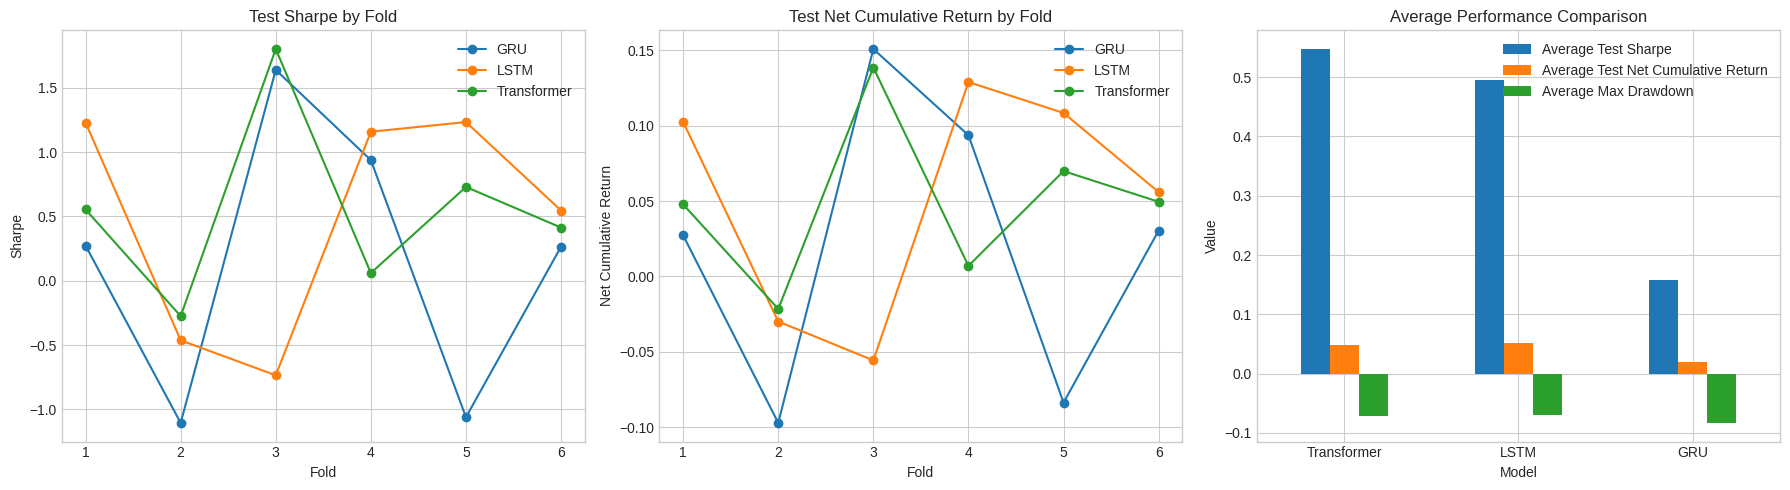

In [10]:
plot_df = deep_learning_fold_results.copy()
plot_df["Fold Number"] = plot_df["Fold"].str.extract(r"(\d+)").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for model_name, part in plot_df.groupby("Model"):
    axes[0].plot(part["Fold Number"], part["Test Sharpe"], marker="o", label=model_name)
axes[0].set_title("Test Sharpe by Fold")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Sharpe")
axes[0].legend()

for model_name, part in plot_df.groupby("Model"):
    axes[1].plot(part["Fold Number"], part["Test Net Cumulative Return"], marker="o", label=model_name)
axes[1].set_title("Test Net Cumulative Return by Fold")
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("Net Cumulative Return")
axes[1].legend()

summary_plot_df = model_summary_df.set_index("Model")[[
    "Average Test Sharpe",
    "Average Test Net Cumulative Return",
    "Average Max Drawdown",
]]
summary_plot_df.plot(kind="bar", ax=axes[2])
axes[2].set_title("Average Performance Comparison")
axes[2].set_ylabel("Value")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## Discussion

In [11]:
discussion_df = model_summary_df.copy()
discussion_df["Rank by Sharpe"] = discussion_df["Average Test Sharpe"].rank(ascending=False, method="dense").astype(int)
discussion_df = discussion_df.sort_values("Rank by Sharpe")

print("Discussion snapshot:")
display(discussion_df.round(4))

print(
    "Interpretation guide: compare models primarily on average test Sharpe and cumulative return, "
    "then use max drawdown and turnover to judge whether any apparent improvement is robust enough "
    "to justify the added sequence-model complexity."
)


Discussion snapshot:


,Model,Average Test Sharpe,Average Test Net Cumulative Return,Average Max Drawdown,Average Turnover,Number of Folds,Rank by Sharpe
0,Transformer,0.5476,0.0485,-0.0722,0.8414,6,1
1,LSTM,0.4953,0.0517,-0.0691,1.1207,6,2
2,GRU,0.1587,0.0202,-0.0832,1.0726,6,3


Interpretation guide: compare models primarily on average test Sharpe and cumulative return, then use max drawdown and turnover to judge whether any apparent improvement is robust enough to justify the added sequence-model complexity.
